# 2. Fix the OSM data once, for every output

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Khoshkhah/duckOSM/blob/main/docs/notebooks/02_osm_fixes.ipynb) <a href="https://khoshkhah.github.io/duckOSM/notebooks/02_osm_fixes.ipynb" download><img src="https://img.shields.io/badge/Download-notebook-F37626?logo=jupyter&logoColor=white" alt="Download the notebook"></a>

OSM data has errors. In duckOSM you write a fix one time, in a fixes file. The build and every export read the file, so all outputs show the corrected data.

In this notebook you change the speed limit of one road (the OSM tag `maxspeed`), build again, and examine the route, the map and six outputs.

In [1]:
# Install duckOSM when it is not installed (for example in Colab). It takes approximately 1 minute.
try:                       # duckosm is there: no install
    import duckosm         # the SDK
except ImportError:        # else install it with the extras of this notebook
    %pip install -q "duckosm[widget,viz,sim]"
    import duckosm         # the SDK
print("duckosm", duckosm.__version__)    # the version

duckosm 0.8.0


## Build Monaco without a fix

In [2]:
area = duckosm.get("Monaco", out="data")    # the OSM file of Monaco and its boundary
net = area.build(modes=["driving"])         # the driving network, with no fixes file
net                                         # the card

cut: 34794 nodes, 5693 ways, 343 relations

Output: data/monaco.duckdb

mode,edges,nodes,km,oneway_km
driving,2840,1768,96.2,35.5


## Find a route

The fastest route by car from Fontvieille to Larvotto. The table shows the OSM ways that the route uses most.

In [3]:
a, b = (7.4155, 43.7285), (7.4335, 43.7468)    # Fontvieille and Larvotto, as (lon, lat)
before = net.route(a, b)                       # the fastest route by car
round(before["time_s"]), round(before["length_m"])    # the time in seconds and the length in metres

(229, 2939)

In [4]:
ways = net.sql("""SELECT osm_id, any_value(name) AS name, any_value(maxspeed_kmh) AS maxspeed_kmh,
                         round(sum(length_m)) AS length_m
                  FROM driving.edges WHERE list_contains($ids, edge_id)
                  GROUP BY osm_id ORDER BY length_m DESC LIMIT 3""", {"ids": before["edges"]})    # the three longest ways of the route
ways

,osm_id,name,maxspeed_kmh,length_m
0,4230891,Boulevard Louis II,50.0,356.0
1,503633031,Avenue Princesse Grace,50.0,223.0
2,166399479,Boulevard Albert 1er,50.0,216.0


## Write the fix

Make the speed limit of the first way 10 km/h, for example for road works. `extra.tag_edits` sets OSM tags. The other keys of the file are in [The fixes file](https://khoshkhah.github.io/duckOSM/guides/edit-osm-data/#the-fixes-file). You can also make fixes on a map with `duckosm edit`.

In [5]:
way = int(ways.osm_id[0])    # the OSM id of the way to fix
fixes = f"""extra:
  tag_edits:
    - {{type: way, id: {way}, set: {{maxspeed: '10'}}}}
"""                                           # one rule: the tag maxspeed of the way
open("osm_fixes.yaml", "w").write(fixes)    # the fixes file
print(fixes)                                # its text

extra:
  tag_edits:
    - {type: way, id: 4230891, set: {maxspeed: '10'}}



## Build again with the fix

In [6]:
fixed = area.build(modes=["driving"], output="data/monaco_fixed.duckdb", fixes="osm_fixes.yaml")    # the same build, with the fixes file
after = fixed.route(a, b)                                                                            # the same route on the fixed network
round(before["time_s"]), round(after["time_s"])                                                      # the seconds before and after the fix

Output: data/monaco_fixed.duckdb

(229, 252)

The new route goes around the slow road. Run the cell to see the live map: you can zoom, and click a road to see its columns. This page shows a picture of the map.

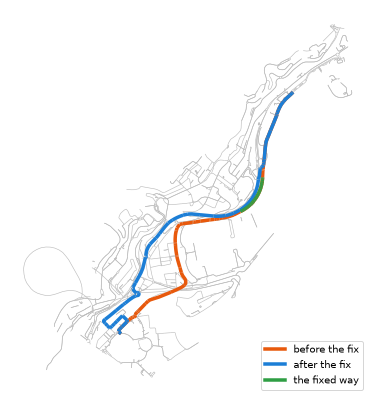

In [7]:
way_edges = {"edges": list(fixed.edges(where=f"osm_id = {way}").edge_id)}                   # the edges of the fixed way, as a route to draw
fixed.map(routes={"before the fix": before, "after the fix": after, "the fixed way": way_edges})    # the three as lines, each in its own color

## The edge ids do not change

A tag fix does not change the shape of the network. So each edge keeps its `edge_id`, and data joined on the ids stays correct.

In [8]:
set(net.edges().edge_id) == set(fixed.edges().edge_id)    # the same edge ids before and after the fix

True

## Every output takes the fix

Each export reads the fixed database, and `quack` reads the fixes file. Each cell writes one output and reads the speed of one edge of the fixed way from it.

In [9]:
import duckdb                                                    # to read the outputs back

edge = way_edges["edges"][0]                                     # one edge of the fixed way
speeds = {"database (km/h)": float(fixed.edges(where=f"edge_id = {edge}").maxspeed_kmh[0])}    # its speed in each output
fixed.to_gis("out/monaco.gpkg")                                  # a GeoPackage
gpkg = duckdb.connect()                                          # DuckDB reads it back
gpkg.load_extension("spatial")                                   # with the extension spatial
speeds["GeoPackage (km/h)"] = gpkg.execute(
    "SELECT maxspeed_kmh FROM st_read('out/monaco.gpkg', layer='edges_driving') WHERE edge_id = ?", [edge]).fetchone()[0]

GIS out/monaco.gpkg: done in 0.1 s

In [10]:
import gzip
import xml.etree.ElementTree as ET                               # to read the XML files back

sumo = fixed.to_sumo("out/sumo", run_netconvert=False)            # the SUMO files; speed in m/s
speeds["SUMO (km/h)"] = round(float(ET.parse(sumo["edg"]).find(f".//edge[@id='{edge}']").get("speed")) * 3.6, 1)
fixed.to_matsim("out/matsim.xml.gz")                             # the MATSim network; free speed in m/s
speeds["MATSim (km/h)"] = round(float(ET.parse(gzip.open("out/matsim.xml.gz")).find(f".//link[@id='{edge}']").get("freespeed")) * 3.6, 1)

SUMO out/sumo: done in 0.1 s

MATSim out/matsim.xml.gz: done in 0.1 s

In [11]:
fixed.to_gmns("out/gmns.duckdb")                                 # the GMNS network: link_id is the edge_id
speeds["GMNS (km/h)"] = duckdb.connect("out/gmns.duckdb", read_only=True).execute(
    "SELECT free_speed FROM gmns_driving.link WHERE link_id = ?", [edge]).fetchone()[0]
quack = duckosm.gis.quack(area, out="out", name="monaco", fixes="osm_fixes.yaml", formats=["geoparquet"])    # the QuackOSM table
speeds["QuackOSM table (tag)"] = gpkg.execute(
    f"SELECT tags['maxspeed'] FROM '{quack[0]}' WHERE feature_id = 'way/{way}'").fetchone()[0]
speeds                                                           # the speed of the edge in each output

GMNS out/gmns.duckdb: done in 9.3 s

out/monaco_quack.parquet

{'database (km/h)': 10.0,
 'GeoPackage (km/h)': 10.0,
 'SUMO (km/h)': 10.0,
 'MATSim (km/h)': 10.0,
 'GMNS (km/h)': 10.0,
 'QuackOSM table (tag)': '10'}